In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
# Environment for testing
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit

import numpy as np
import itertools as it
import matplotlib.pyplot as plt

In [ ]:
# Agents
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
# Utils 
from pyCRLD.Utils.Trajectories1D import trajectories_1D
from pyCRLD.Utils.PhasePlot import phaseplot

In [ ]:
env1 = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)
env1

TwoArmedBandit_1_-1_0.3_0.1

In [ ]:
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env2 = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)
env2

DistTwoArmedBanditOneState_1_-1_0.3_0.1

In [ ]:
mae1 = stratSARSA(env=env1, learning_rates=0.1, discount_factors=0, choice_intensities=4., use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
mae2 = qbaseSARSA(env2,
                  nr_reward_bins=29,
                  discretization_sigma=0.1,
                  learning_rates=0.1,
                  discount_factors=0,
                  choice_intensities=4.,
                  Rmin=-2,
                  Rmax=2,
                  use_prefactor=False)

In [ ]:
x = ([0], [0, 1, 2], [0])
res = np.linspace(0, 1., 11)

array([<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>,
       <Axes: title={'center': 'state 1'}, xlabel='step'>,
       <Axes: title={'center': 'state 2'}, xlabel='step'>], dtype=object)

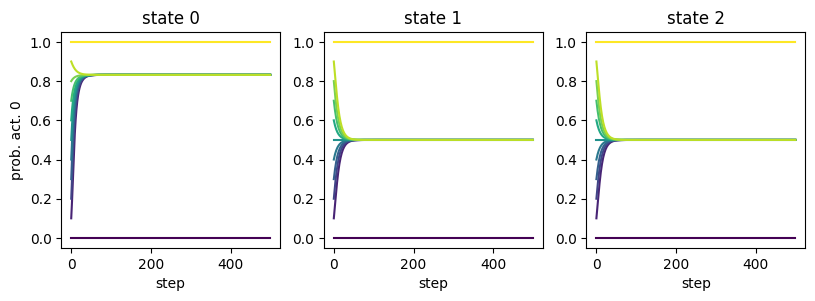

In [ ]:
trajectories_1D(mae1, x, res, NrRandom=4)

In [ ]:
x = ([0], [0], [0])

[<Axes: title={'center': 'state 0'}, xlabel='step', ylabel='prob. act. 0'>]

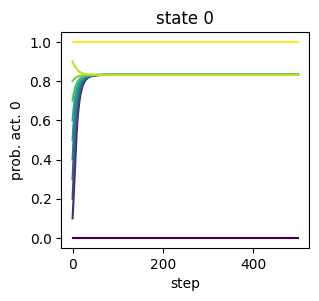

In [ ]:
trajectories_1D(mae2, x, res, NrRandom=4)

In [ ]:
x = ([0], [0, 1, 2], [0]) 
res = np.linspace(0, 1., 41)
res[0] = 0.0001
res[-1] = 0.9999

array([<Axes: title={'center': 'state 0'}, xlabel='prob. act. 0', ylabel='RPE'>,
       <Axes: title={'center': 'state 1'}, xlabel='prob. act. 0'>,
       <Axes: title={'center': 'state 2'}, xlabel='prob. act. 0'>],
      dtype=object)

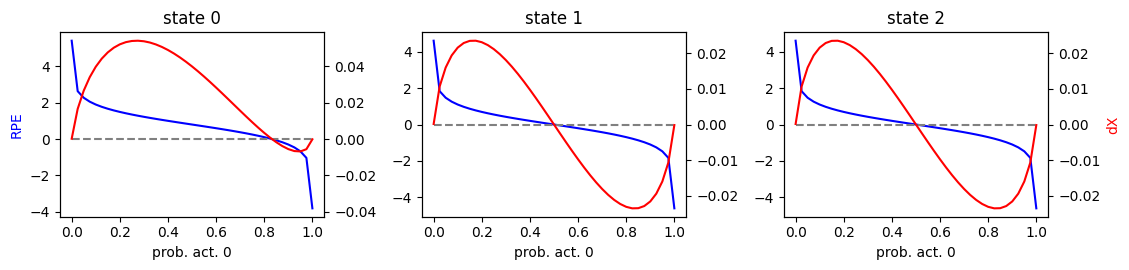

In [ ]:
phaseplot(mae1, x, res, NrRandom=1)

[<Axes: title={'center': 'state 0'}, xlabel='prob. act. 0', ylabel='RPE'>]

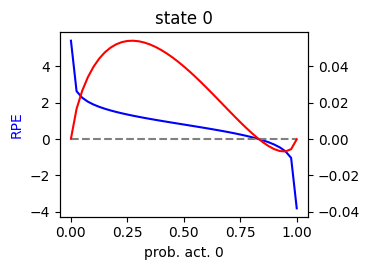

In [ ]:
x = ([0], [0], [0]) 
phaseplot(mae2, x, res, NrRandom=1)